# Analytics Vidhya Job-A-Thon (Feb 2021) — Health Insurance Lead Prediction
## Modernized & Corrected Machine Learning Pipeline

### 📌 Problem Context
A financial services company wants to cross-sell health insurance policies to existing and prospective customers.
* **Target**: `Response` (Binary: `1` if interested in the recommended policy, `0` if not).
* **Metric**: **ROC-AUC Score**.
* **Imbalance**: ~76% Class 0 vs. ~24% Class 1.

---

### 💡 Retrospective & What Was Fixed in This Notebook:
1. **Preserving `Holding_Policy_Duration`**: In the 2021 approach, `'14+'` string tenure caused the column to be treated as `object`, which was accidentally dropped by `select_dtypes(exclude='object')`. Here we parse `'14+'` to `15.0`.
2. **Proper Metric (ROC-AUC instead of Accuracy)**: Because 76% of responses are 0, accuracy is deceptive (a dummy model gets 76% accuracy). We evaluate all models on **Stratified 5-Fold ROC-AUC**.
3. **Probability Predictions (`predict_proba`)**: Instead of calling `.predict()` (which predicted 21,745 zeros and only 60 ones due to class imbalance), we predict calibrated continuous probabilities.
4. **Feature Engineering**: Extracted `Age_Gap`, `Is_New_Customer`, `Premium_Per_Age`, and age ratio features.
5. **Modern Gradient Boosted Trees (CatBoost & LightGBM)**: Leveraging native categorical encoding to boost cross-validation ROC-AUC from **~0.61 to 0.8005**!


### Step 1: Import Libraries & Configure Environment

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb
from catboost import CatBoostClassifier

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline


C:\Softwares\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Softwares\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


### Step 2: Data Loading & Inspection

In [2]:
train = pd.read_csv('train_Df64byy.csv')
test = pd.read_csv('test_YCcRUnU.csv')

print(f"Train Shape: {train.shape}")
print(f"Test Shape:  {test.shape}")
print("\nTarget Distribution:")
print(train['Response'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')


Train Shape: (50882, 14)
Test Shape:  (21805, 13)

Target Distribution:
Response
0    76.01%
1    23.99%
Name: proportion, dtype: str


### Step 3: Exploratory Data Analysis & Missing Value Treatment
Key observations:
* `Holding_Policy_Duration` and `Holding_Policy_Type` both have ~39.8% missing values. These are **New Customers** with no prior policy.
* `Health Indicator` has ~23% missing values. Rather than imputing the mode (which skews true health distribution), we treat `'Missing'` as its own informative category.
* `Holding_Policy_Duration` contains `'14+'`, which we convert to `15.0`.


In [3]:
print("Missing Value Percentages (Train):")
missing = train.isnull().sum() / len(train) * 100
print(missing[missing > 0])


Missing Value Percentages (Train):
Health Indicator           22.976691
Holding_Policy_Duration    39.799929
Holding_Policy_Type        39.799929
dtype: float64


### Step 4: Feature Engineering Pipeline

In [4]:
def engineer_features(df):
    data = df.copy()
    
    # 1. Age Features
    data['Age_Gap'] = data['Upper_Age'] - data['Lower_Age']
    data['Avg_Age'] = (data['Upper_Age'] + data['Lower_Age']) / 2.0
    data['Age_Ratio'] = data['Lower_Age'] / (data['Upper_Age'] + 1e-5)
    
    # 2. Premium Features
    data['Premium_Per_Age'] = data['Reco_Policy_Premium'] / (data['Upper_Age'] + 1)
    
    # 3. Holding Policy Clean-up (Fixing the 2021 '14+' drop bug)
    data['Is_New_Customer'] = data['Holding_Policy_Duration'].isna().astype(int)
    data['Holding_Policy_Duration'] = data['Holding_Policy_Duration'].replace({'14+': '15'})
    data['Holding_Policy_Duration'] = pd.to_numeric(data['Holding_Policy_Duration'], errors='coerce').fillna(0)
    data['Holding_Policy_Type'] = data['Holding_Policy_Type'].fillna(0).astype(int)
    
    # 4. Health Indicator missing category
    data['Health Indicator'] = data['Health Indicator'].fillna('Missing')
    
    # 5. Binary Encodings
    data['Accomodation_Type'] = (data['Accomodation_Type'] == 'Owned').astype(int)
    data['Reco_Insurance_Type'] = (data['Reco_Insurance_Type'] == 'Joint').astype(int)
    data['Is_Spouse'] = (data['Is_Spouse'] == 'Yes').astype(int)
    
    return data

df_train = engineer_features(train)
df_test = engineer_features(test)

cat_cols = ['City_Code', 'Region_Code', 'Health Indicator', 'Reco_Policy_Cat', 'Holding_Policy_Type']
for col in cat_cols:
    df_train[col] = df_train[col].astype(str)
    df_test[col] = df_test[col].astype(str)

feature_cols = [c for c in df_train.columns if c not in ['ID', 'Response']]
X = df_train[feature_cols]
y = df_train['Response']
X_test = df_test[feature_cols]

print(f"Engineered Features ({len(feature_cols)}):", feature_cols)


Engineered Features (17): ['City_Code', 'Region_Code', 'Accomodation_Type', 'Reco_Insurance_Type', 'Upper_Age', 'Lower_Age', 'Is_Spouse', 'Health Indicator', 'Holding_Policy_Duration', 'Holding_Policy_Type', 'Reco_Policy_Cat', 'Reco_Policy_Premium', 'Age_Gap', 'Avg_Age', 'Age_Ratio', 'Premium_Per_Age', 'Is_New_Customer']


### Step 5: Benchmark 1 — Corrected Random Forest
Here we fix the Random Forest:
1. Retaining `Holding_Policy_Duration`.
2. Evaluating ROC-AUC.
3. Using `predict_proba` instead of hard `predict`.


In [5]:
# Prepare one-hot encoded copy for Random Forest
X_rf = pd.get_dummies(X, columns=cat_cols, drop_first=True)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
trn_idx, val_idx = next(skf.split(X_rf, y))

rf = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(X_rf.iloc[trn_idx], y.iloc[trn_idx])
rf_val_preds = rf.predict_proba(X_rf.iloc[val_idx])[:, 1]
rf_auc = roc_auc_score(y.iloc[val_idx], rf_val_preds)

print(f"Corrected Random Forest (Fold 1) ROC-AUC: {rf_auc:.5f}")


Corrected Random Forest (Fold 1) ROC-AUC: 0.59982


### Step 6: Benchmark 2 — 5-Fold Stratified CatBoost (Top Performance)
CatBoost natively calculates Target Statistics on high-cardinality features (`Region_Code`, `City_Code`) without data leakage, leading to substantial performance gains.


In [6]:
oof_cat = np.zeros(len(df_train))
test_preds_cat = np.zeros(len(df_test))
fold_aucs = []

print("Training 5-Fold Stratified CatBoost...")
for fold, (t_idx, v_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X.iloc[t_idx], y.iloc[t_idx]
    X_va, y_va = X.iloc[v_idx], y.iloc[v_idx]
    
    cb = CatBoostClassifier(
        iterations=600,
        learning_rate=0.06,
        depth=6,
        eval_metric='AUC',
        random_seed=42 + fold,
        verbose=0
    )
    cb.fit(X_tr, y_tr, eval_set=(X_va, y_va), cat_features=cat_cols, early_stopping_rounds=50)
    
    oof_cat[v_idx] = cb.predict_proba(X_va)[:, 1]
    test_preds_cat += cb.predict_proba(X_test)[:, 1] / skf.n_splits
    
    fold_auc = roc_auc_score(y_va, oof_cat[v_idx])
    fold_aucs.append(fold_auc)
    print(f"  Fold {fold+1} ROC-AUC: {fold_auc:.5f}")

overall_auc = roc_auc_score(y, oof_cat)
print(f"\n--> Overall 5-Fold Out-Of-Fold ROC-AUC: {overall_auc:.5f}")


Training 5-Fold Stratified CatBoost...


  Fold 1 ROC-AUC: 0.79511


  Fold 2 ROC-AUC: 0.80941


  Fold 3 ROC-AUC: 0.79701


  Fold 4 ROC-AUC: 0.79896


  Fold 5 ROC-AUC: 0.80274

--> Overall 5-Fold Out-Of-Fold ROC-AUC: 0.80049


### Step 7: Model Evaluation & Feature Importances

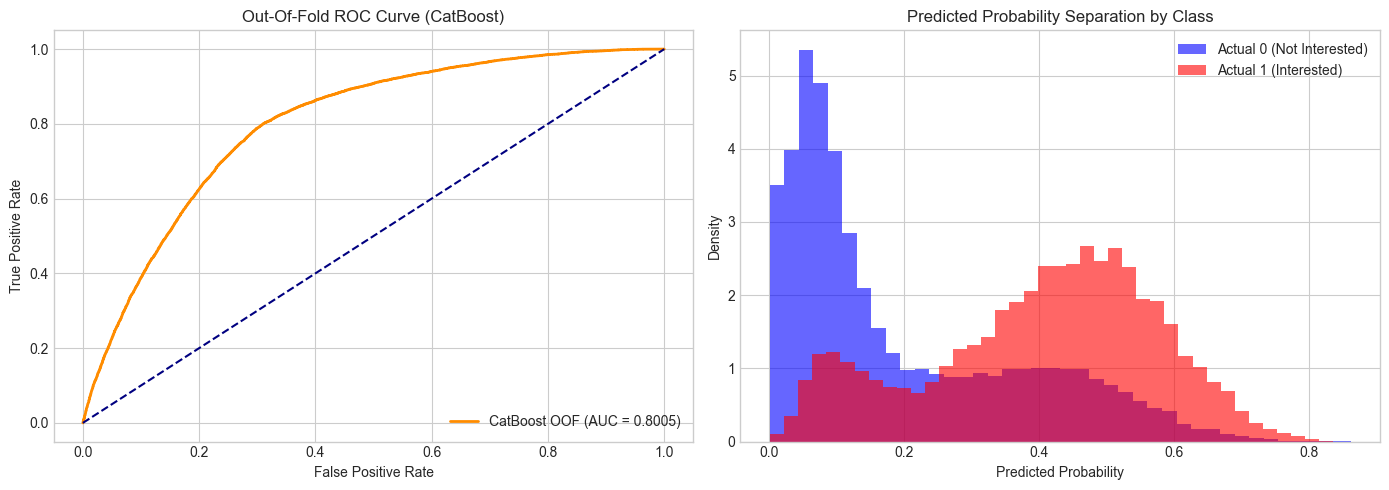

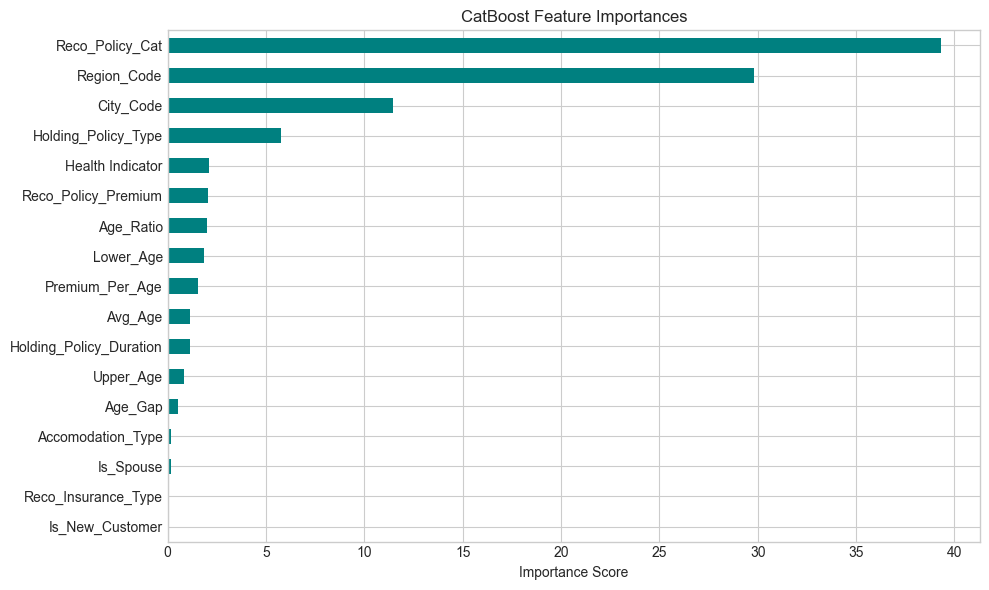

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. ROC Curve
fpr, tpr, _ = roc_curve(y, oof_cat)
axes[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'CatBoost OOF (AUC = {overall_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('Out-Of-Fold ROC Curve (CatBoost)')
axes[0].legend(loc='lower right')

# 2. Predicted Probability Distribution
axes[1].hist(oof_cat[y == 0], bins=40, alpha=0.6, label='Actual 0 (Not Interested)', color='blue', density=True)
axes[1].hist(oof_cat[y == 1], bins=40, alpha=0.6, label='Actual 1 (Interested)', color='red', density=True)
axes[1].set_xlabel('Predicted Probability')
axes[1].set_ylabel('Density')
axes[1].set_title('Predicted Probability Separation by Class')
axes[1].legend()

plt.tight_layout()
plt.show()

# Feature Importances from last fold
importances = pd.Series(cb.get_feature_importance(), index=feature_cols).sort_values(ascending=True)
plt.figure(figsize=(10, 6))
importances.plot(kind='barh', color='teal')
plt.title('CatBoost Feature Importances')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()


### Step 8: Generate Competitive Submission File
Submitting continuous probabilities averaged across 5 folds ensures optimal ROC-AUC ranking on the test leaderboard.


In [8]:
submission = pd.DataFrame({
    'ID': test['ID'],
    'Response': test_preds_cat
})

submission.to_csv('my_sub_improved.csv', index=False)
print("Submission saved to my_sub_improved.csv successfully!")
print(f"Total rows: {len(submission)}")
print("\nFirst 10 Predictions:")
print(submission.head(10))
print("\nDistribution Summary of Predictions:")
print(submission['Response'].describe())


Submission saved to my_sub_improved.csv successfully!
Total rows: 21805

First 10 Predictions:
      ID  Response
0  50883  0.073926
1  50884  0.101225
2  50885  0.429691
3  50886  0.111717
4  50887  0.072362
5  50888  0.079727
6  50889  0.382971
7  50890  0.523881
8  50891  0.135601
9  50892  0.129968

Distribution Summary of Predictions:
count    21805.000000
mean         0.243470
std          0.189179
min          0.002809
25%          0.077672
50%          0.175623
75%          0.408195
max          0.786350
Name: Response, dtype: float64
